# VALORA AI: Better Data, Better Predictions
## Notebook 04: final evaluation, uncertainty, sensitivity and the final approach

This notebook answers the central question:

> **Do richer property features provide reliable predictive value beyond a price-per-square-meter baseline for appraised apartments in Budva?**

**Steps:**
1. **Paired comparison with the strongest baseline**, on the same properties and folds, for:
   - the nested selection procedure (NS, the primary ML estimate);
   - the pre-specified hypothesis H1 (Ridge, set A).
2. **Decision rule:** outcome A, B or C (`docs/EVALUATION_PROTOCOL.md`, section 10).
3. **Sensitivity analyses:**
   - without the most valuable properties;
   - rounded appraisals only;
   - building-level grouping;
   - other baseline minimums;
   - the temporal split.
4. **Error analysis:** actual vs predicted, residuals, error by value range, largest errors.
5. **The final chart and the final recommended approach.**

It reads the cross-validation results saved by notebook 03.

**What this code does:** Sets up the paths and loads the modelling table and the results of notebook 03.

**Why we need it:** The final evaluation uses exactly the saved predictions; nothing is re-tuned here.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
while not (ROOT / 'src' / 'budva_data.py').exists():      # works when started from notebooks/ or from the project root
    if ROOT.parent == ROOT:
        raise FileNotFoundError('Start Jupyter inside the VALORA_BUDVA_APPRAISAL_EXPERIMENT folder')
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / 'src'))

import numpy as np
import pandas as pd
from IPython.display import Image, display

pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 200)
pd.set_option('display.max_colwidth', 90)

import json
import budva_data as bd
import budva_eval as be
import budva_plots as bp
from budva_models import BASELINES, BASELINE_SENSITIVITY, PricePerM2Baseline
m = bd.load_model_table()
preds = pd.read_csv(bd.RESULTS_DIR / 'cv_predictions.csv')
folds = pd.read_csv(bd.RESULTS_DIR / 'cv_fold_scores.csv')
summary = pd.read_csv(bd.RESULTS_DIR / 'cv_summary.csv')
strongest = be.strongest_baseline(summary)
label = {**{k: v[0] for k, v in BASELINES.items()}, be.NS: 'Nested selection (NS)', be.H1: 'Ridge, set A (H1)'}
print('strongest baseline:', label[strongest])
print(summary.loc[summary['kind'] == 'baseline', ['model_id', 'MAE', 'MAE_min', 'MAE_max', 'RMSE', 'R2']].round(1).to_string(index=False))

strongest baseline: B3 Year median €/m² × area
model_id     MAE  MAE_min  MAE_max     RMSE   R2
      B0 78318.0  76683.0  80258.0 120013.6 -0.1
      B1 45041.8  44447.5  46898.9  69439.3  0.6
      B2 46173.1  42327.8  47445.1  67914.8  0.7
      B3 45030.5  43364.9  48506.0  71197.2  0.6
      B4 46311.0  42417.5  48446.7  69239.7  0.6


## 1. Paired comparison with the strongest baseline

- **D** = baseline MAE − model MAE. A positive D means the model's errors are smaller.
- **Evidence collected for each method:**
  - the mean and the range of D over the 10 repeats;
  - the number of repeats and of the 50 folds in which the model is better;
  - a 95% interval of D from a **cluster bootstrap** (resampling the 73 valuation clusters, 5,000 times).

**What this code does:** Compares NS, H1 and every individual candidate with the strongest baseline, and saves the table.

**Why we need it:** The decision must rest on a paired comparison with its uncertainty, not on one average.

In [2]:
rows = []
for mid in [be.NS, be.H1] + [c for c in summary.loc[summary['kind'] == 'candidate', 'model_id'] if c != be.H1]:
    c = be.paired_comparison(preds, mid, strongest)
    c['outcome'] = be.decision(c)
    c['role'] = {be.NS: 'primary (protocol)', be.H1: 'pre-specified hypothesis'}.get(mid, 'descriptive only')
    rows.append(c)
paired = pd.DataFrame(rows)
paired.to_csv(bd.RESULTS_DIR / 'paired_comparisons.csv', index=False, encoding='utf-8', lineterminator='\n')
cols = ['model', 'role', 'baseline_MAE', 'model_MAE', 'D_eur', 'D_pct', 'D_min', 'D_max', 'repeats_model_better',
        'folds_model_better', 'CI95_low', 'CI95_high', 'outcome']
paired[cols].round(1)

,model,role,baseline_MAE,model_MAE,D_eur,D_pct,D_min,D_max,repeats_model_better,folds_model_better,CI95_low,CI95_high,outcome
0,NS: nested selection,primary (protocol),45030.5,42250.1,2780.4,6.2,-2040.4,5921.1,8,36,-2806.0,8583.9,B: promising but uncertain
1,Ridge | A,pre-specified hypothesis,45030.5,42657.6,2372.9,5.3,-1224.2,4784.0,9,33,-2219.6,7174.7,B: promising but uncertain
2,Linear Regression | A,descriptive only,45030.5,45334.4,-303.9,-0.7,-3785.2,3127.6,4,23,-7297.8,6984.0,C: no improvement
3,Linear Regression | B,descriptive only,45030.5,47705.2,-2674.7,-5.9,-6830.2,2978.3,2,21,-9879.0,4643.1,C: no improvement
4,Linear Regression | C,descriptive only,45030.5,48580.1,-3549.7,-7.9,-9704.0,1421.3,2,23,-12061.5,5733.5,C: no improvement
5,Ridge | B,descriptive only,45030.5,40049.2,4981.2,11.1,2980.7,7201.1,10,38,-846.7,11121.4,B: promising but uncertain
6,Ridge | C,descriptive only,45030.5,41130.6,3899.8,8.7,-3344.1,7338.5,9,35,-2992.1,11521.5,B: promising but uncertain
7,Lasso | A,descriptive only,45030.5,42838.1,2192.3,4.9,229.0,4717.7,10,36,-807.4,5573.3,B: promising but uncertain
8,Lasso | B,descriptive only,45030.5,40001.6,5028.9,11.2,3215.8,7198.9,10,38,-3.5,10856.1,B: promising but uncertain
9,Lasso | C,descriptive only,45030.5,38922.9,6107.5,13.6,1946.6,8460.5,10,43,-465.8,12911.2,B: promising but uncertain


**Important:**
- **The decision uses only the first two rows.**
  - NS is the primary estimate. It includes the cost of choosing among 18 candidates.
  - H1 was named before the run.
- **The other rows are descriptive.** With 18 candidates, some will look better than the baseline by chance. Picking the best of them after seeing the outer results would be the optimistic selection that the protocol forbids.

**What this code does:** Compares NS also with each of the five baselines.

**Why we need it:** It shows how much of any gain is relative to the simple rules and how much relative to the strongest one.

In [3]:
vs_all = pd.DataFrame([{**be.paired_comparison(preds, be.NS, b), 'baseline_name': label[b]} for b in BASELINES])
vs_all[['baseline_name', 'baseline_MAE', 'model_MAE', 'D_eur', 'D_pct', 'repeats_model_better', 'CI95_low', 'CI95_high']].round(1)

,baseline_name,baseline_MAE,model_MAE,D_eur,D_pct,repeats_model_better,CI95_low,CI95_high
0,B0 Global median value,78318.0,42250.1,36068.0,46.1,10,21233.2,51188.3
1,B1 Budva median €/m² × area,45041.8,42250.1,2791.8,6.2,8,-2399.8,7403.5
2,B2 Neighbourhood median €/m² × area,46173.1,42250.1,3923.0,8.5,9,-2659.3,10294.4
3,B3 Year median €/m² × area,45030.5,42250.1,2780.4,6.2,8,-2806.0,8583.9
4,B4 Neighbourhood €/m² × year index × area,46311.0,42250.1,4061.0,8.8,8,-2313.1,10390.4


## 2. Decision (protocol section 10)

**What this code does:** Applies the locked decision rule to NS and to H1 and prints the result.

**Why we need it:** The outcome follows mechanically from the pre-registered criteria.

In [4]:
ns_c = paired[paired['model'] == be.NS].iloc[0]
h1_c = paired[paired['model'] == be.H1].iloc[0]
for c in (ns_c, h1_c):
    print(f"{label[c['model']]:24s} vs {label[strongest]}:")
    print(f"   D = €{c['D_eur']:,.0f} ({c['D_pct']:+.1f}%), 95% interval €{c['CI95_low']:,.0f} to €{c['CI95_high']:,.0f}, "
          f"better in {c['repeats_model_better']}/10 repeats and {c['folds_model_better']}/50 folds")
    print('   -> outcome', c['outcome'])

Nested selection (NS)    vs B3 Year median €/m² × area:
   D = €2,780 (+6.2%), 95% interval €-2,806 to €8,584, better in 8/10 repeats and 36/50 folds
   -> outcome B: promising but uncertain
Ridge, set A (H1)        vs B3 Year median €/m² × area:
   D = €2,373 (+5.3%), 95% interval €-2,220 to €7,175, better in 9/10 repeats and 33/50 folds
   -> outcome B: promising but uncertain


## 3. Sensitivity analyses

**What this code does:** Repeats the paired comparison of NS and H1 without the 4 most valuable properties and on rounded appraisals only.

**Why we need it:** A result driven by a few expensive properties, or by allocated values, would not be robust.

In [5]:
top4 = set(m.nlargest(4, 'market_value_eur')['property_id'])
rounded = set(m.loc[m['value_basis'] == 'rounded_appraisal', 'property_id'])
masks = {'all 80 properties': None,
         'without the 4 most valuable': lambda p: ~p['property_id'].isin(top4),
         f'rounded appraisals only ({len(rounded)})': lambda p: p['property_id'].isin(rounded)}
sens = []
for name, mask in masks.items():
    for mid in (be.NS, be.H1):
        c = be.paired_comparison(preds, mid, strongest, mask=mask)
        sens.append({'subset': name, 'model': label[mid], 'n': c['n_properties'], 'baseline_MAE': c['baseline_MAE'],
                     'model_MAE': c['model_MAE'], 'D_eur': c['D_eur'], 'D_pct': c['D_pct'],
                     'repeats_model_better': c['repeats_model_better'], 'CI95_low': c['CI95_low'], 'CI95_high': c['CI95_high']})
sens = pd.DataFrame(sens)
sens.round(1)

,subset,model,n,baseline_MAE,model_MAE,D_eur,D_pct,repeats_model_better,CI95_low,CI95_high
0,all 80 properties,Nested selection (NS),80,45030.5,42250.1,2780.4,6.2,8,-2806.0,8583.9
1,all 80 properties,"Ridge, set A (H1)",80,45030.5,42657.6,2372.9,5.3,9,-2219.6,7174.7
2,without the 4 most valuable,Nested selection (NS),76,36495.6,33984.7,2510.9,6.9,9,-3061.3,8147.4
3,without the 4 most valuable,"Ridge, set A (H1)",76,36495.6,33877.6,2618.0,7.2,10,-1343.0,6592.7
4,rounded appraisals only (65),Nested selection (NS),65,41254.0,40684.0,570.0,1.4,5,-5538.0,6327.3
5,rounded appraisals only (65),"Ridge, set A (H1)",65,41254.0,38381.5,2872.5,7.0,9,-2284.1,7840.6


**What this code does:** Evaluates the baselines with other minimum numbers of training properties per neighbourhood (2 and 5) on the same folds.

**Why we need it:** The minimum of 3 was fixed in advance; this shows whether another reasonable choice would change the strongest baseline.

In [6]:
bp_preds, bp_folds, _ = be.run_nested_cv(m, candidates=[], baselines=BASELINE_SENSITIVITY, n_jobs=1)
bsum = be.per_repeat_metrics(bp_preds).groupby('model_id')['MAE'].agg(['mean', 'min', 'max'])
bsum.index = [BASELINE_SENSITIVITY[i][0] for i in bsum.index]
base_main = summary.loc[summary['kind'] == 'baseline'].set_index('model_id')[['MAE', 'MAE_min', 'MAE_max']]
base_main.index = [label[i] for i in base_main.index]
base_main.columns = ['mean', 'min', 'max']
baseline_sens = pd.concat([base_main, bsum]).round(0)
baseline_sens.to_csv(bd.RESULTS_DIR / 'baseline_sensitivity.csv', encoding='utf-8', lineterminator='\n')
baseline_sens

,mean,min,max
B0 Global median value,78318.0,76683.0,80258.0
B1 Budva median €/m² × area,45042.0,44448.0,46899.0
B2 Neighbourhood median €/m² × area,46173.0,42328.0,47445.0
B3 Year median €/m² × area,45030.0,43365.0,48506.0
B4 Neighbourhood €/m² × year index × area,46311.0,42418.0,48447.0
B2 with minimum 2,46989.0,44558.0,48733.0
B2 with minimum 5,48309.0,46222.0,49550.0
B4 with minimum 2,47356.0,44985.0,49912.0
B4 with minimum 5,47881.0,45791.0,49819.0


**What this code does:** Re-runs baselines, NS and H1 with stricter grouping by building (neighbourhood + construction year), 3 repeats.

**Why we need it:** Several buildings were appraised more than once; grouping whole buildings checks that the result does not depend on comparables from the same building.

In [7]:
bld_preds, bld_folds, _ = be.run_nested_cv(m, groups_col='building_key', n_repeats=3, n_jobs=2)
bld = be.per_repeat_metrics(bld_preds).groupby('model_id')['MAE'].agg(['mean', 'min', 'max'])
bld_strongest = bld.loc[list(BASELINES), 'mean'].idxmin()
bld_rows = []
for mid in (be.NS, be.H1):
    c = be.paired_comparison(bld_preds, mid, bld_strongest)
    bld_rows.append({'model': label[mid], 'strongest baseline (building grouping)': label[bld_strongest],
                     'baseline_MAE': c['baseline_MAE'], 'model_MAE': c['model_MAE'], 'D_eur': c['D_eur'], 'D_pct': c['D_pct'],
                     'repeats_model_better': f"{c['repeats_model_better']}/3", 'CI95_low': c['CI95_low'], 'CI95_high': c['CI95_high']})
building = pd.DataFrame(bld_rows)
building.to_csv(bd.RESULTS_DIR / 'building_grouping_sensitivity.csv', index=False, encoding='utf-8', lineterminator='\n')
print('buildings:', m['building_key'].nunique())
display(bld.loc[list(BASELINES) + [be.NS, be.H1]].round(0))
building.round(1)

buildings: 40


,mean,min,max
model_id,,,
B0,77491.0,77333.0,77796.0
B1,45074.0,44681.0,45463.0
B2,46340.0,44358.0,47987.0
B3,46977.0,45557.0,48016.0
B4,47486.0,46940.0,48142.0
NS: nested selection,41176.0,40403.0,41726.0
Ridge | A,46538.0,43350.0,49109.0


,model,strongest baseline (building grouping),baseline_MAE,model_MAE,D_eur,D_pct,repeats_model_better,CI95_low,CI95_high
0,Nested selection (NS),B1 Budva median €/m² × area,45073.7,41175.6,3898.2,8.6,3/3,-1805.9,9486.1
1,"Ridge, set A (H1)",B1 Budva median €/m² × area,45073.7,46537.9,-1464.2,-3.2,1/3,-7462.0,3873.6


### Temporal sensitivity split (2021-2025 → 2026)

- **Not an untouched test.** This split was looked at in an earlier exploratory run, so it is not independent confirmation; it is reported only as a sensitivity check.
- **Tuning:** inner grouped CV on the 2021-2025 data only.

**What this code does:** Trains every method on 2021-2025 (tuning by inner grouped CV on those years only) and evaluates on the 2026 appraisals.

**Why we need it:** It checks whether the conclusion also holds when predicting a later period, which is how a valuation model would be used.

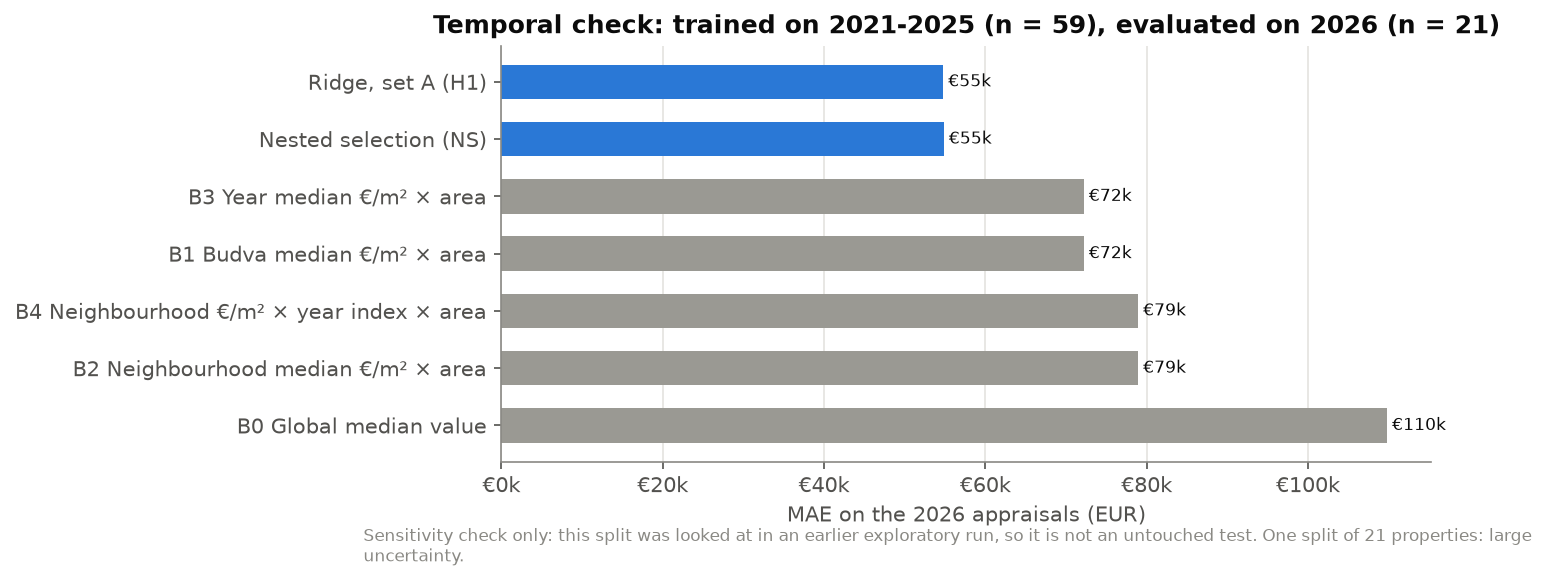

2026 evaluation: best baseline B1 Budva median €/m² × area €72,213
Nested selection (NS): €54,855 (chosen: Elastic Net | C)
Ridge, set A (H1): €54,779 


,label,kind,MAE,train_mae,best_params
13,Lasso | C,candidate,54461.0,26571.0,alpha=0.03
15,Elastic Net | B,candidate,54626.0,28012.0,"alpha=0.03, l1_ratio=0.5"
8,"Ridge, set A (H1)",candidate,54779.0,26000.0,alpha=3
16,Elastic Net | C,candidate,54855.0,23546.0,"alpha=0.03, l1_ratio=0.5"
23,Nested selection (NS),nested selection,54855.0,23546.0,Elastic Net | C
11,Lasso | A,candidate,54879.0,27093.0,alpha=0.01
14,Elastic Net | A,candidate,55359.0,26528.0,"alpha=0.03, l1_ratio=0.2"
12,Lasso | B,candidate,55592.0,29192.0,alpha=0.03
9,Ridge | B,candidate,55900.0,24883.0,alpha=3
5,Linear Regression | A,candidate,57261.0,23575.0,


In [8]:
t_preds, t_folds = be.temporal_split(m)
t = t_folds[['model_id', 'kind', 'test_mae', 'train_mae', 'best_params']].copy()
t['label'] = t['model_id'].map(lambda x: label.get(x, x))
t = t.rename(columns={'test_mae': 'MAE'})
t.to_csv(bd.RESULTS_DIR / 'temporal_check.csv', index=False, encoding='utf-8', lineterminator='\n')
n_tr, n_te = int((m['appraisal_year'] <= 2025).sum()), int((m['appraisal_year'] > 2025).sum())
display(Image(bp.temporal(t[(t['kind'] != 'candidate') | (t['model_id'] == be.H1)], n_tr, n_te)))
t_best_baseline = t[t['kind'] == 'baseline'].sort_values('MAE').iloc[0]
print('2026 evaluation: best baseline', t_best_baseline['label'], f"€{t_best_baseline['MAE']:,.0f}")
for mid in (be.NS, be.H1):
    r_ = t[t['model_id'] == mid].iloc[0]
    print(f"{label[mid]}: €{r_['MAE']:,.0f}", '(chosen: ' + r_['best_params'] + ')' if mid == be.NS else '')
t.sort_values('MAE')[['label', 'kind', 'MAE', 'train_mae', 'best_params']].round(0)

## 4. Error analysis

**What this code does:** Averages each property's out-of-fold predictions over the 10 repeats for the strongest baseline, NS and H1.

**Why we need it:** Averaged out-of-fold predictions give one honest prediction per property for the plots.

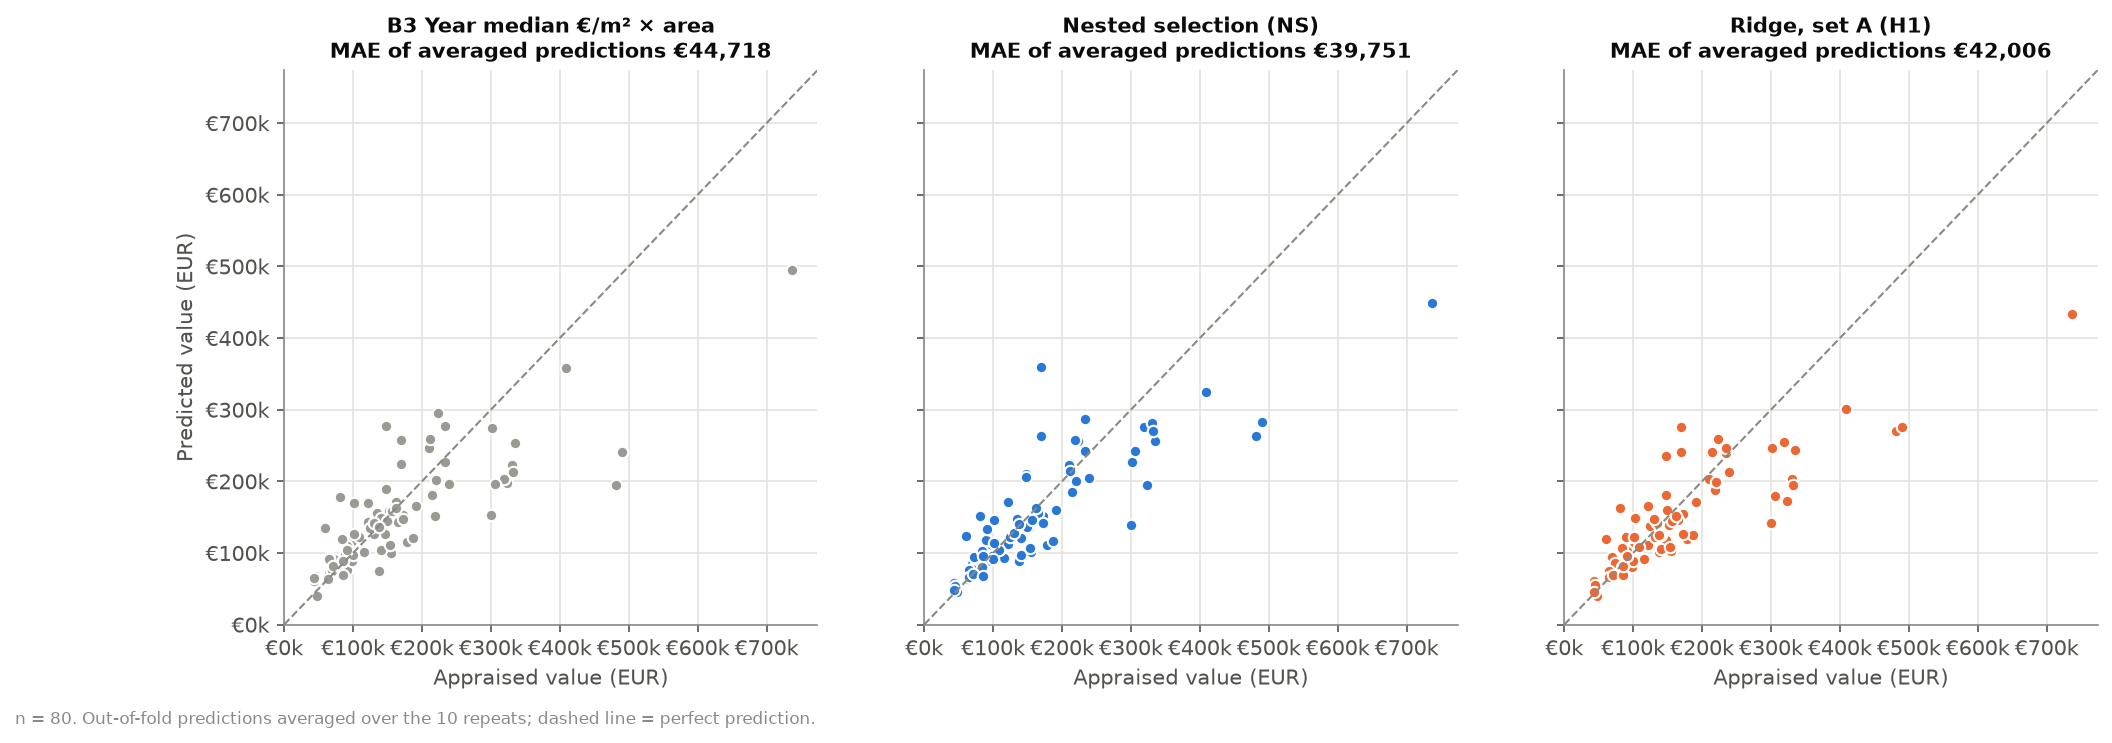

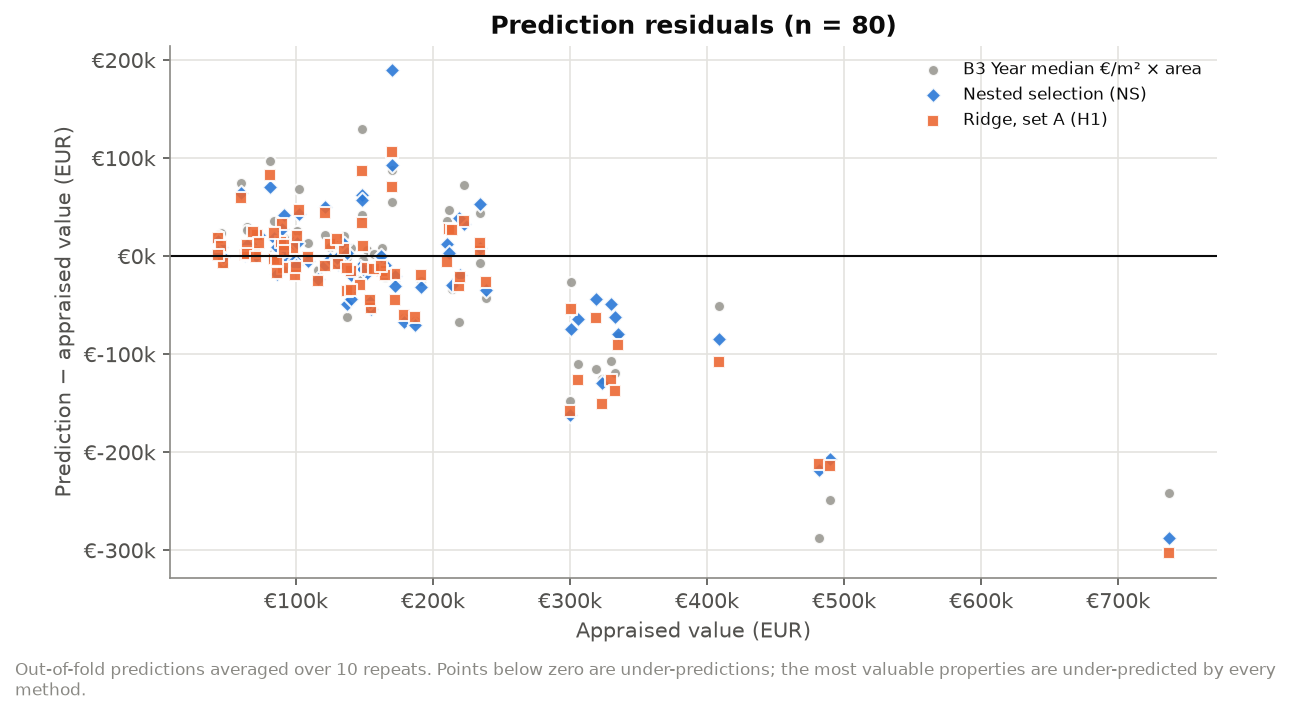

In [9]:
ids = [strongest, be.NS, be.H1]
labels = [label[i] for i in ids]
colors = [bp.GREY, bp.BLUE, bp.ORANGE]
oof = preds[preds['model_id'].isin(ids)].groupby(['model_id', 'property_id'], as_index=False).agg(y_true=('y_true', 'first'), y_pred=('y_pred', 'mean'))
oof.to_csv(bd.RESULTS_DIR / 'oof_mean_predictions.csv', index=False, encoding='utf-8', lineterminator='\n')
display(Image(bp.actual_vs_predicted(oof, ids, labels, colors, len(m))))
display(Image(bp.residuals(oof, ids, labels, colors, len(m))))

**What this code does:** Computes the error by value tertile (about 27 properties each) and draws it.

**Why we need it:** It shows whether a method helps for cheap, middle or expensive properties; tertiles keep every group at 26 or more properties.

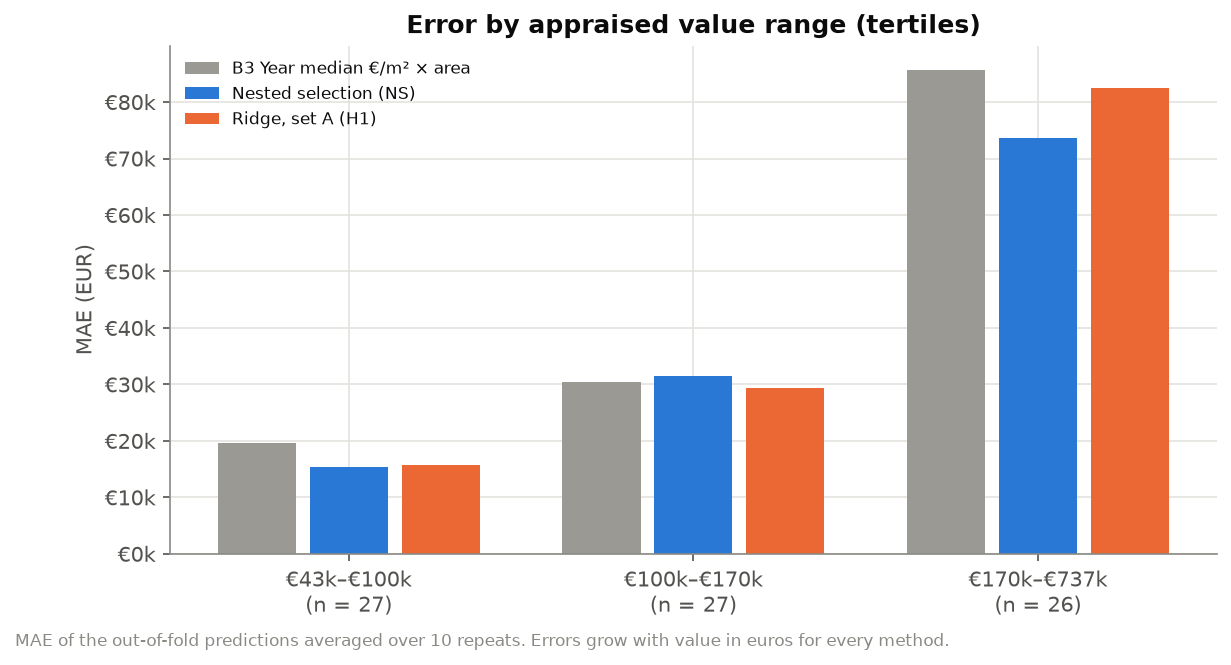

MAE                                 MAPE                               
model_id          B3 NS: nested selection Ridge | A    B3 NS: nested selection Ridge | A
band                                                                                    
€43k–€100k   19610.6              15391.4   15684.1  28.4                 21.1      21.6
€100k–€170k  30351.5              31556.9   29404.8  21.9                 21.7      20.6
€170k–€737k  85709.4              73556.5   82427.5  26.6                 22.4      24.7

In [10]:
cut = pd.qcut(m.set_index('property_id')['market_value_eur'], 3)
names = {iv: f'€{iv.left / 1000:,.0f}k–€{iv.right / 1000:,.0f}k' for iv in cut.cat.categories}
o = oof.assign(band=oof['property_id'].map(cut).map(names))
o['abs_error'] = (o['y_pred'] - o['y_true']).abs()
o['pct_error'] = 100 * o['abs_error'] / o['y_true']
by_range = o.groupby(['band', 'model_id'], sort=False, observed=True).agg(n=('abs_error', 'size'), MAE=('abs_error', 'mean'),
                                                                        MAPE=('pct_error', 'mean')).reset_index()
order = [names[c] for c in cut.cat.categories]
by_range['band'] = pd.Categorical(by_range['band'], order, ordered=True)
by_range = by_range.sort_values(['band', 'model_id']).reset_index(drop=True)
by_range['band'] = by_range['band'].astype(str)
by_range.to_csv(bd.RESULTS_DIR / 'error_by_price_range.csv', index=False, encoding='utf-8', lineterminator='\n')
display(Image(bp.error_by_range(by_range, ids, labels, colors)))
by_range.pivot(index='band', columns='model_id', values=['MAE', 'MAPE']).loc[order].round(1)

**What this code does:** Lists the properties with the largest errors of NS, with the baseline error for comparison.

**Why we need it:** Looking at individual misses shows what the models cannot see (for example a special location or a very large flat).

In [11]:
w = oof.pivot(index='property_id', columns='model_id', values='y_pred')
info = m.set_index('property_id')[['neighborhood_group', 'appraisal_year', 'area_m2', 'view_type', 'value_basis', 'market_value_eur']]
err = info.assign(NS_pred=w[be.NS], baseline_pred=w[strongest])
err['NS_error'] = err['NS_pred'] - err['market_value_eur']
err['baseline_error'] = err['baseline_pred'] - err['market_value_eur']
err.reindex(err['NS_error'].abs().sort_values(ascending=False).index).head(8).round(0)

,neighborhood_group,appraisal_year,area_m2,view_type,value_basis,market_value_eur,NS_pred,baseline_pred,NS_error,baseline_error
property_id,,,,,,,,,,
P019,Zavala,2026,190,sea,rounded_appraisal,737000.0,449050.0,494875.0,-287950.0,-242125.0
P033,Centar,2022,117,urban,rounded_appraisal,482000.0,263836.0,194836.0,-218164.0,-287164.0
P065,Rafailovići,2025,102,sea,rounded_appraisal,490000.0,283393.0,241045.0,-206607.0,-248955.0
P054,Gospoština,2025,107,urban,rounded_appraisal,170000.0,359436.0,257658.0,189436.0,87658.0
P043,Dubovica,2023,77,urban,rounded_appraisal,300000.0,138380.0,152502.0,-161620.0,-147498.0
P018,Zavala,2026,76,sea,allocated_appraisal,323308.0,194262.0,197950.0,-129046.0,-125358.0
P052,Rafailovići,2025,94,sea,rounded_appraisal,170000.0,262910.0,224803.0,92910.0,54803.0
P017,Sveti Stefan,2026,131,sea,rounded_appraisal,409000.0,324549.0,358470.0,-84451.0,-50530.0


## 5. The final chart: baseline vs best validated model

**What this code does:** Draws the main result chart: the MAE of the strongest baseline and of the validated ML procedure, and their paired difference with its 95% interval.

**Why we need it:** This is the central picture of the presentation; it shows the size and the uncertainty of the difference together.

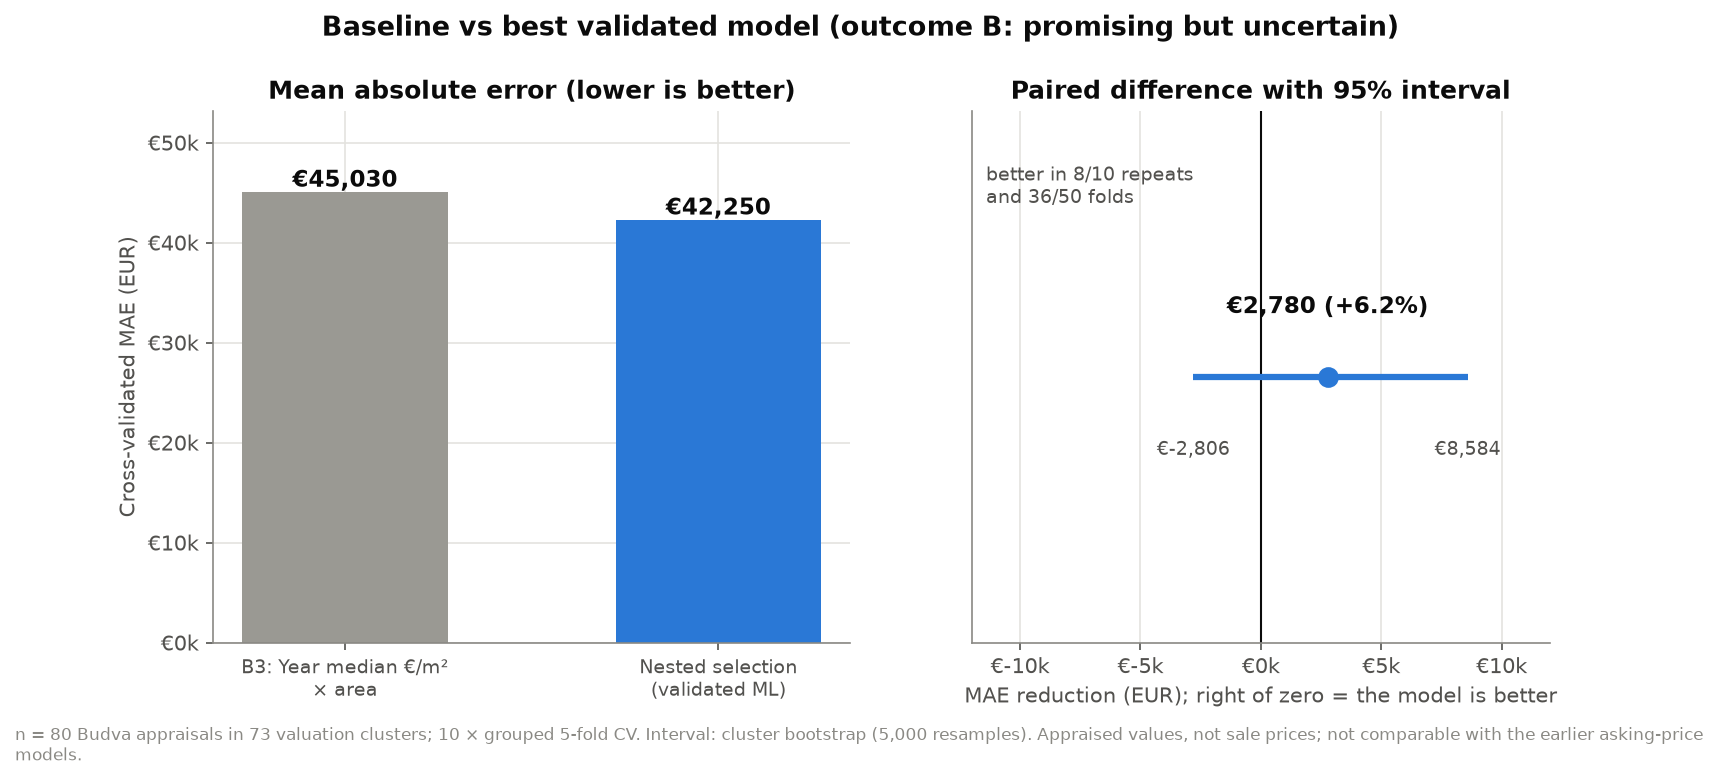

In [12]:
final = dict(ns_c)
final.update({'baseline_label': label[strongest].replace(' × area', '\n× area').replace('B4 ', 'B4: ').replace('B2 ', 'B2: ').replace('B1 ', 'B1: ').replace('B3 ', 'B3: '),
              'model_label': 'Nested selection\n(validated ML)', 'outcome': ns_c['outcome']})
display(Image(bp.final_chart(final, len(m), m['valuation_cluster'].nunique())))

## 6. Final approach

**What this code does:** Applies the protocol: if NS reached outcome A it is refitted on all 80 properties; otherwise the strongest baseline is fitted on all 80 and saved as the recommended rule.

**Why we need it:** The recommendation must follow the decision rule, not the most attractive number.

In [13]:
final_method = {'decision_outcome_NS': ns_c['outcome'], 'decision_outcome_H1': h1_c['outcome'], 'strongest_baseline': strongest,
                'strongest_baseline_name': label[strongest]}
if ns_c['outcome'].startswith('A'):
    import joblib
    chosen, gs = be.fit_nested_selection(m)
    joblib.dump(gs.best_estimator_, ROOT / 'results' / 'final_model.joblib')
    final_method['recommended'] = f'nested selection procedure refitted on all data (chose {chosen})'
else:
    rule = BASELINES[strongest][1].fit(m[be.ALL_FEATURES], m['market_value_eur'].to_numpy(float))
    final_method['recommended'] = label[strongest] + ' (fitted on all 80 properties)'
    final_method['budva_rate_eur_m2'] = round(rule.rate_, 2)
    if strongest in ('B2', 'B4'):
        final_method['neighbourhood_rates_eur_m2'] = {k: round(v, 2) for k, v in sorted(rule.nb_rate_.items())}
    if strongest in ('B3', 'B4'):
        final_method['year_rates_eur_m2'] = {str(k): round(v, 2) for k, v in sorted(rule.year_rate_.items())}
        final_method['note'] = ('a year without at least 5 appraisals (for example a future year) falls back to the Budva rate, '
                                'so the rule cannot follow a price trend beyond the last appraisal year')
    final_method['rule'] = ('value = neighbourhood median €/m² (if ≥ 3 properties, else Budva median) × year index × area; '
                            'year index = year median €/m² / Budva median €/m² (1 if fewer than 5 properties)'
                            if strongest == 'B4' else BASELINES[strongest][0])
(bd.RESULTS_DIR / 'final_method.json').write_text(json.dumps(final_method, indent=2, ensure_ascii=False), encoding='utf-8')
print(json.dumps(final_method, indent=2, ensure_ascii=False))

{
  "decision_outcome_NS": "B: promising but uncertain",
  "decision_outcome_H1": "B: promising but uncertain",
  "strongest_baseline": "B3",
  "strongest_baseline_name": "B3 Year median €/m² × area",
  "recommended": "B3 Year median €/m² × area (fitted on all 80 properties)",
  "budva_rate_eur_m2": 2281.21,
  "year_rates_eur_m2": {
    "2022": 1672.78,
    "2023": 1984.98,
    "2025": 2382.35,
    "2026": 2720.93
  },
  "note": "a year without at least 5 appraisals (for example a future year) falls back to the Budva rate, so the rule cannot follow a price trend beyond the last appraisal year",
  "rule": "B3 Year median €/m² × area"
}


**What this code does:** Collects the key numbers quoted in the documents into one file.

**Why we need it:** Every document is checked against this file by an automatic test, so all documents report the same final results.

In [14]:
def r0(x):
    return int(round(float(x)))
cand_best = paired[paired['role'] == 'descriptive only'].sort_values('model_MAE').iloc[0]
abc = pd.read_csv(bd.RESULTS_DIR / 'feature_set_comparison.csv', index_col=0)
key = {
    'n_properties': len(m), 'n_reports': int(m['report_group'].nunique()), 'n_clusters': int(m['valuation_cluster'].nunique()),
    'n_buildings': int(m['building_key'].nunique()),
    'strongest_baseline': label[strongest],
    'baseline_MAE': {label[b]: r0(summary.set_index('model_id').loc[b, 'MAE']) for b in BASELINES},
    'NS_MAE': r0(ns_c['model_MAE']), 'H1_MAE': r0(h1_c['model_MAE']), 'strongest_baseline_MAE': r0(ns_c['baseline_MAE']),
    'NS_D_eur': r0(ns_c['D_eur']), 'NS_D_pct': round(float(ns_c['D_pct']), 1),
    'NS_CI95': [r0(ns_c['CI95_low']), r0(ns_c['CI95_high'])], 'NS_repeats_better': int(ns_c['repeats_model_better']),
    'NS_folds_better': int(ns_c['folds_model_better']), 'NS_outcome': ns_c['outcome'],
    'H1_D_eur': r0(h1_c['D_eur']), 'H1_D_pct': round(float(h1_c['D_pct']), 1),
    'H1_CI95': [r0(h1_c['CI95_low']), r0(h1_c['CI95_high'])], 'H1_repeats_better': int(h1_c['repeats_model_better']),
    'H1_folds_better': int(h1_c['folds_model_better']), 'H1_outcome': h1_c['outcome'],
    'best_individual_candidate': cand_best['model'], 'best_individual_candidate_MAE': r0(cand_best['model_MAE']),
    'feature_set_best_per_model': abc['best set'].to_dict(),
    'temporal_best_baseline': t_best_baseline['label'], 'temporal_best_baseline_MAE': r0(t_best_baseline['MAE']),
    'temporal_NS_MAE': r0(t.loc[t['model_id'] == be.NS, 'MAE'].iloc[0]), 'temporal_H1_MAE': r0(t.loc[t['model_id'] == be.H1, 'MAE'].iloc[0]),
    'recommended': final_method['recommended'],
}
(bd.RESULTS_DIR / 'key_numbers.json').write_text(json.dumps(key, indent=2, ensure_ascii=False), encoding='utf-8')
print(json.dumps(key, indent=2, ensure_ascii=False))

{
  "n_properties": 80,
  "n_reports": 76,
  "n_clusters": 73,
  "n_buildings": 40,
  "strongest_baseline": "B3 Year median €/m² × area",
  "baseline_MAE": {
    "B0 Global median value": 78318,
    "B1 Budva median €/m² × area": 45042,
    "B2 Neighbourhood median €/m² × area": 46173,
    "B3 Year median €/m² × area": 45030,
    "B4 Neighbourhood €/m² × year index × area": 46311
  },
  "NS_MAE": 42250,
  "H1_MAE": 42658,
  "strongest_baseline_MAE": 45030,
  "NS_D_eur": 2780,
  "NS_D_pct": 6.2,
  "NS_CI95": [
    -2806,
    8584
  ],
  "NS_repeats_better": 8,
  "NS_folds_better": 36,
  "NS_outcome": "B: promising but uncertain",
  "H1_D_eur": 2373,
  "H1_D_pct": 5.3,
  "H1_CI95": [
    -2220,
    7175
  ],
  "H1_repeats_better": 9,
  "H1_folds_better": 33,
  "H1_outcome": "B: promising but uncertain",
  "best_individual_candidate": "Elastic Net | C",
  "best_individual_candidate_MAE": 37946,
  "feature_set_best_per_model": {
    "Linear Regression": "A",
    "Ridge": "B",
    "Lasso": 

## 7. Conclusion

The conclusion, written from the numbers above, is in `docs/MODEL_COMPARISON.md` and `docs/RESEARCH_STORY.md`. An automatic test checks that both quote the numbers in `results/key_numbers.json`.